# Gráficas de la comparativa OCR: Tesseract vs Unlimited-OCR

In [ ]:
import csv
import json
import os
from collections import defaultdict

import matplotlib.pyplot as plt
import numpy as np

# --- Configuración -------------------------------------------------------------------
CARPETA_RESULTADOS = 'resultados-5b'
CARPETA_DATASET = 'plates_ocr'
CARPETA_GRAFICAS = 'graficas'
DPI = 150

os.makedirs(CARPETA_GRAFICAS, exist_ok=True)

# Colores fijos por modelo
COLORES = ['#2a78d6', '#eb6834']
NOMBRES = {'tesseract': 'Tesseract', 'unlimited-ocr': 'Unlimited-OCR'}

plt.rcParams.update({
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#9a9a96', 'axes.labelcolor': '#3a3a38',
    'xtick.color': '#5a5a57', 'ytick.color': '#5a5a57',
    'axes.grid': True, 'axes.axisbelow': True,
    'grid.color': '#e6e5e0', 'grid.linewidth': 0.8,
    'font.size': 10, 'axes.titlesize': 12, 'axes.titleweight': 'bold',
    'legend.frameon': False,
})

## Carga de datos

In [4]:
with open(os.path.join(CARPETA_RESULTADOS, 'resultados.csv'), newline='', encoding='utf-8') as fh:
    filas = list(csv.DictReader(fh))

for f in filas:
    for k in ('acierto_exacto', 'distancia_edicion', 'salida_vacia'):
        f[k] = int(f[k])
    for k in ('cer', 't_inferencia_ms', 't_preproceso_ms'):
        f[k] = float(f[k])

# Orden de los modelos: el de aparición en el CSV (así el color de cada modelo no cambia)
modelos = list(dict.fromkeys(f['modelo'] for f in filas))
color = {m: COLORES[i % len(COLORES)] for i, m in enumerate(modelos)}
nombre = {m: NOMBRES.get(m, m) for m in modelos}
por_modelo = {m: [f for f in filas if f['modelo'] == m] for m in modelos}

resumen_csv = {}
ruta = os.path.join(CARPETA_RESULTADOS, 'resumen.csv')
if os.path.exists(ruta):
    with open(ruta, newline='', encoding='utf-8') as fh:
        resumen_csv = {r['modelo']: r for r in csv.DictReader(fh) if r['subconjunto'] == 'todas'}

for m in modelos:
    print(f'{nombre[m]:<15} {len(por_modelo[m])} imágenes')

Tesseract       175 imágenes
Unlimited-OCR   175 imágenes


## Métricas por modelo y subconjunto

In [5]:
def metricas(fs):
    n = len(fs)
    if n == 0:
        return None
    acc = sum(f['acierto_exacto'] for f in fs) / n
    # Intervalo de Wilson al 95 %: a diferencia del normal, no da ±0 cuando el acierto es 0 o 1
    z = 1.96
    centro = (acc + z**2 / (2*n)) / (1 + z**2 / n)
    margen = z * np.sqrt(acc*(1-acc)/n + z**2/(4*n**2)) / (1 + z**2 / n)
    t = np.array([f['t_inferencia_ms'] for f in fs])
    return {
        'n': n, 'exact': acc, 'ic_bajo': centro - margen, 'ic_alto': centro + margen,
        'cer': sum(f['distancia_edicion'] for f in fs) / sum(len(f['referencia']) for f in fs),
        'vacias': sum(f['salida_vacia'] for f in fs) / n,
        't_media': t.mean(), 't_mediana': np.median(t), 't_p95': np.percentile(t, 95),
    }

def por_grupo(campo, orden=None):
    grupos = orden or sorted({f[campo] for f in filas})
    return grupos, {m: {g: metricas([f for f in por_modelo[m] if f[campo] == g]) for g in grupos} for m in modelos}

global_ = {m: metricas(por_modelo[m]) for m in modelos}

## Tabla resumen

In [6]:
cab = ['Modelo', 'Acierto exacto (IC 95 %)', 'CER', 'Salidas vacías',
       'Latencia mediana', 'Latencia p95', 'Imágenes/s', 'Carga modelo', 'Memoria GPU pico']
print('| ' + ' | '.join(cab) + ' |')
print('|' + '---|' * len(cab))
for m in modelos:
    g = global_[m]
    r = resumen_csv.get(m, {})
    carga = f"{float(r['t_carga_modelo_s']):.1f} s" if r.get('t_carga_modelo_s') else '–'
    mem = f"{float(r['mem_gpu_pico_mb'])/1024:.1f} GB" if r.get('mem_gpu_pico_mb') else '–'
    print(f"| {nombre[m]} | {g['exact']*100:.1f} % ({g['ic_bajo']*100:.1f}–{g['ic_alto']*100:.1f}) "
          f"| {g['cer']:.3f} | {g['vacias']*100:.1f} % | {g['t_mediana']:.1f} ms | {g['t_p95']:.1f} ms "
          f"| {1000/g['t_media']:.1f} | {carga} | {mem} |")


| Modelo | Acierto exacto (IC 95 %) | CER | Salidas vacías | Latencia mediana | Latencia p95 | Imágenes/s | Carga modelo | Memoria GPU pico |
|---|---|---|---|---|---|---|---|---|
| Tesseract | 1.1 % (0.3–4.1) | 0.876 | 53.7 % | 56.5 ms | 65.4 ms | 17.5 | 0.0 s | – |
| Unlimited-OCR | 17.7 % (12.8–24.0) | 2.033 | 38.3 % | 434.5 ms | 2306.5 ms | 1.8 | 6.2 s | 6.8 GB |


## 1. Tasa de acierto

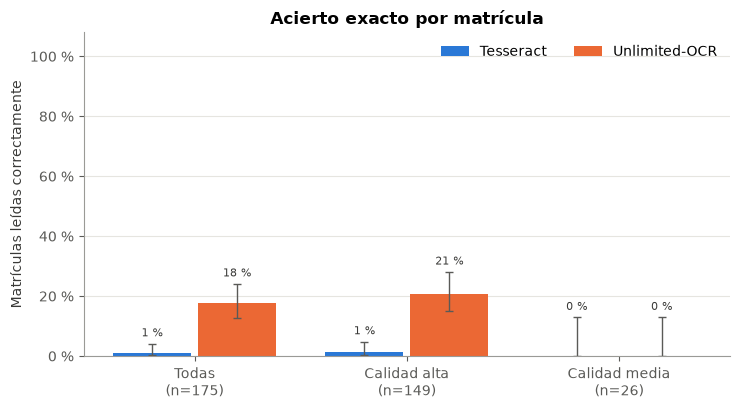

In [ ]:
def barras_agrupadas(ax, grupos, datos, clave, etiquetas_grupo, fmt, err=False, ymax=None):
    x = np.arange(len(grupos))
    ancho = 0.8 / len(modelos)
    for i, m in enumerate(modelos):
        vals = np.array([datos[m][g][clave] if datos[m][g] else np.nan for g in grupos])
        pos = x - 0.4 + ancho * (i + 0.5)
        kw = {}
        if err:
            bajo = np.array([datos[m][g]['ic_bajo'] if datos[m][g] else np.nan for g in grupos])
            alto = np.array([datos[m][g]['ic_alto'] if datos[m][g] else np.nan for g in grupos])
            kw = dict(yerr=[vals - bajo, alto - vals], capsize=3,
                      error_kw=dict(ecolor='#5a5a57', elinewidth=1, capthick=1))
        ax.bar(pos, vals, ancho * 0.92, color=color[m], label=nombre[m], zorder=2, **kw)
        for p, v in zip(pos, vals):
            if not np.isnan(v):
                y = (alto[list(pos).index(p)] if err else v)
                ax.text(p, y + (ymax or 1) * 0.015, fmt(v), ha='center', va='bottom', fontsize=8, color='#3a3a38')
    ax.set_xticks(x, etiquetas_grupo)
    ax.grid(axis='x', visible=False)
    if ymax:
        ax.set_ylim(0, ymax)

grupos = ['todas', 'alta', 'media']
datos = {m: {'todas': global_[m],
             'alta': metricas([f for f in por_modelo[m] if f['quality'] == 'alta']),
             'media': metricas([f for f in por_modelo[m] if f['quality'] == 'media'])} for m in modelos}
etq = [f"{g.capitalize() if g != 'todas' else 'Todas'}\n(n={datos[modelos[0]][g]['n'] if datos[modelos[0]][g] else 0})"
       for g in grupos]
etq = [e.replace('Alta', 'Calidad alta').replace('Media', 'Calidad media') for e in etq]

fig, ax = plt.subplots(figsize=(7.5, 4.2))
barras_agrupadas(ax, grupos, datos, 'exact', etq, lambda v: f'{v*100:.0f} %', err=True, ymax=1.08)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v*100:.0f} %'))
ax.set_ylabel('Matrículas leídas correctamente')
ax.set_title('Acierto exacto por matrícula')
ax.legend(loc='upper right', ncol=len(modelos))
fig.tight_layout()
fig.savefig(f'{CARPETA_GRAFICAS}/01_acierto_exacto.png', dpi=DPI)
plt.show()

## 2. Error por carácter (CER)

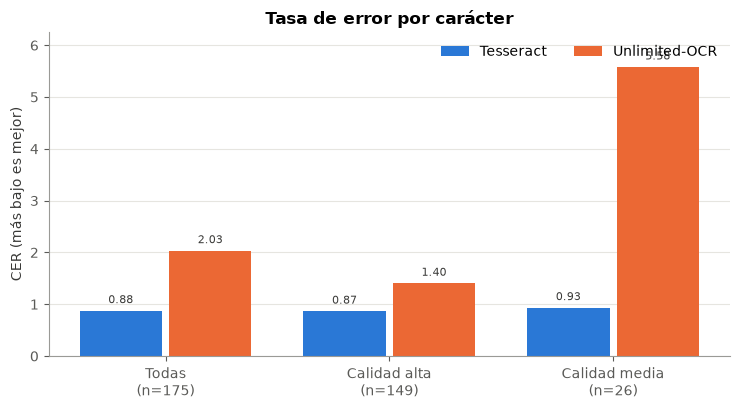

In [8]:
fig, ax = plt.subplots(figsize=(7.5, 4.2))
cer_max = max(datos[m][g]['cer'] for m in modelos for g in grupos if datos[m][g])
barras_agrupadas(ax, grupos, datos, 'cer', etq, lambda v: f'{v:.2f}', ymax=max(1.0, cer_max * 1.12))
ax.set_ylabel('CER (más bajo es mejor)')
ax.set_title('Tasa de error por carácter')
ax.legend(loc='upper right', ncol=len(modelos))
fig.tight_layout()
fig.savefig(f'{CARPETA_GRAFICAS}/02_cer.png', dpi=DPI)
plt.show()

## 3. Distribución de errores por matrícula

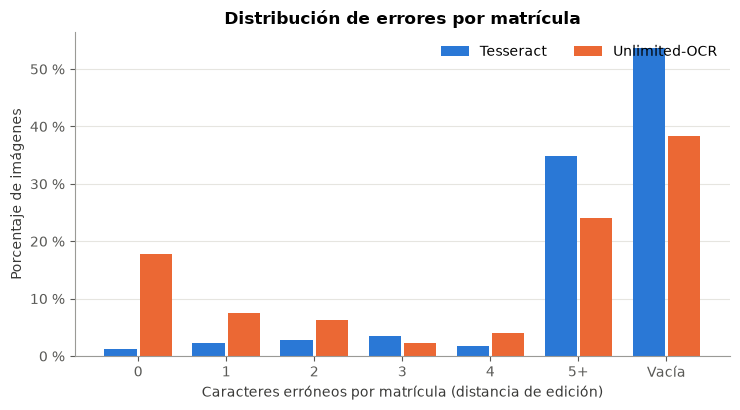

In [9]:
categorias = ['0', '1', '2', '3', '4', '5+', 'Vacía']
def categoria(f):
    if f['salida_vacia']:
        return 'Vacía'
    d = f['distancia_edicion']
    return '5+' if d >= 5 else str(d)

fig, ax = plt.subplots(figsize=(7.5, 4.2))
x = np.arange(len(categorias))
ancho = 0.8 / len(modelos)
for i, m in enumerate(modelos):
    n = len(por_modelo[m])
    cuenta = defaultdict(int)
    for f in por_modelo[m]:
        cuenta[categoria(f)] += 1
    vals = np.array([cuenta[c] / n for c in categorias])
    ax.bar(x - 0.4 + ancho * (i + 0.5), vals, ancho * 0.92, color=color[m], label=nombre[m], zorder=2)
ax.set_xticks(x, categorias)
ax.grid(axis='x', visible=False)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v*100:.0f} %'))
ax.set_xlabel('Caracteres erróneos por matrícula (distancia de edición)')
ax.set_ylabel('Porcentaje de imágenes')
ax.set_title('Distribución de errores por matrícula')
ax.legend(loc='upper right', ncol=len(modelos))
fig.tight_layout()
fig.savefig(f'{CARPETA_GRAFICAS}/03_distribucion_errores.png', dpi=DPI)
plt.show()

## 4. Acierto por tipo de matrícula

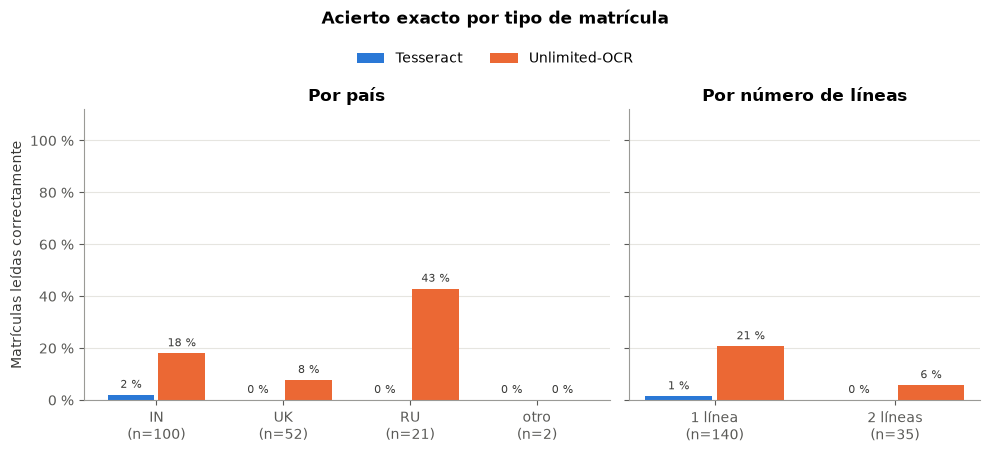

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4.2), sharey=True,
                               gridspec_kw={'width_ratios': [3, 2]})

paises, dp = por_grupo('country', [p for p in ['IN', 'UK', 'RU', 'otro'] if any(f['country'] == p for f in filas)])
barras_agrupadas(ax1, paises, dp, 'exact',
                 [f"{p}\n(n={dp[modelos[0]][p]['n']})" for p in paises], lambda v: f'{v*100:.0f} %', ymax=1.12)
ax1.set_title('Por país')
ax1.set_ylabel('Matrículas leídas correctamente')

lineas, dl = por_grupo('lines', ['1', '2'])
barras_agrupadas(ax2, lineas, dl, 'exact',
                 [f"{l} línea{'s' if l != '1' else ''}\n(n={dl[modelos[0]][l]['n']})" for l in lineas],
                 lambda v: f'{v*100:.0f} %', ymax=1.12)
ax2.set_title('Por número de líneas')

ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v*100:.0f} %'))
handles, labels = ax1.get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', ncol=len(modelos), bbox_to_anchor=(0.5, 1.0))
fig.suptitle('Acierto exacto por tipo de matrícula', fontweight='bold', y=1.07)
fig.tight_layout()
fig.savefig(f'{CARPETA_GRAFICAS}/04_acierto_por_tipo.png', dpi=DPI, bbox_inches='tight')
plt.show()

## 5. Tiempo de inferencia por imagen

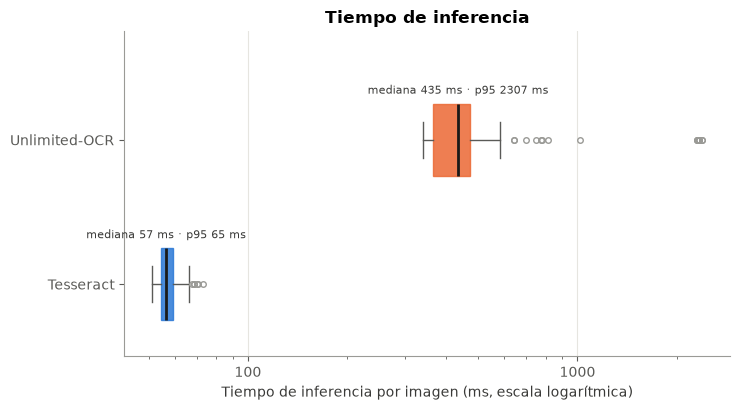

In [11]:
fig, ax = plt.subplots(figsize=(7.5, 4.2))
tiempos = [[f['t_inferencia_ms'] for f in por_modelo[m]] for m in modelos]
estilo_caja = dict(patch_artist=True, widths=0.5,
                medianprops=dict(color='#1a1a19', linewidth=2),
                whiskerprops=dict(color='#5a5a57'), capprops=dict(color='#5a5a57'),
                flierprops=dict(marker='o', markersize=4, markerfacecolor='none', markeredgecolor='#9a9a96'))
try:
    bp = ax.boxplot(tiempos, orientation='horizontal', **estilo_caja)  # matplotlib >= 3.10
except TypeError:
    bp = ax.boxplot(tiempos, vert=False, **estilo_caja)                # versiones anteriores
for caja, m in zip(bp['boxes'], modelos):
    caja.set_facecolor(color[m]); caja.set_alpha(0.85); caja.set_edgecolor(color[m])
ax.set_yticks(range(1, len(modelos) + 1), [nombre[m] for m in modelos])
ax.set_xscale('log')
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:g}'))
ax.set_xlabel('Tiempo de inferencia por imagen (ms, escala logarítmica)')
ax.grid(axis='y', visible=False)
for i, m in enumerate(modelos, 1):
    g = global_[m]
    ax.annotate(f"mediana {g['t_mediana']:.0f} ms · p95 {g['t_p95']:.0f} ms", (g['t_mediana'], i + 0.3),
                ha='center', va='bottom', fontsize=8, color='#3a3a38')
ax.set_ylim(0.5, len(modelos) + 0.75)
ax.set_title('Tiempo de inferencia')
fig.tight_layout()
fig.savefig(f'{CARPETA_GRAFICAS}/05_tiempo_inferencia.png', dpi=DPI)
plt.show()

## 6. Compromiso velocidad / acierto

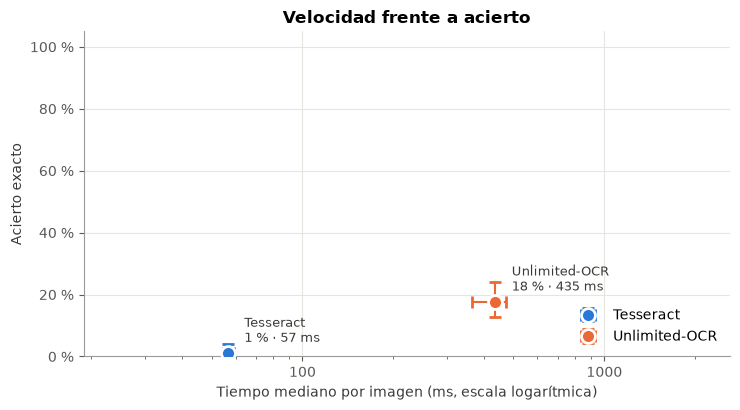

In [12]:
fig, ax = plt.subplots(figsize=(7.5, 4.2))
for m in modelos:
    g = global_[m]
    t = np.array([f['t_inferencia_ms'] for f in por_modelo[m]])
    q1, q3 = np.percentile(t, [25, 75])
    ax.errorbar(g['t_mediana'], g['exact'],
                xerr=[[g['t_mediana'] - q1], [q3 - g['t_mediana']]],
                yerr=[[g['exact'] - g['ic_bajo']], [g['ic_alto'] - g['exact']]],
                fmt='o', markersize=10, color=color[m], ecolor=color[m], elinewidth=1.5, capsize=4,
                markeredgecolor='white', markeredgewidth=2, zorder=3, label=nombre[m])
    ax.annotate(f"{nombre[m]}\n{g['exact']*100:.0f} % · {g['t_mediana']:.0f} ms", (g['t_mediana'], g['exact']),
                xytext=(12, 8), textcoords='offset points', fontsize=9, color='#3a3a38')
ax.set_xscale('log')
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:g}'))
xs = [global_[m]['t_mediana'] for m in modelos]
ax.set_xlim(min(xs) / 3, max(xs) * 6)
ax.set_ylim(0, 1.05)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v*100:.0f} %'))
ax.set_xlabel('Tiempo mediano por imagen (ms, escala logarítmica)')
ax.set_ylabel('Acierto exacto')
ax.set_title('Velocidad frente a acierto')
ax.legend(loc='lower right')
fig.tight_layout()
fig.savefig(f'{CARPETA_GRAFICAS}/06_velocidad_vs_acierto.png', dpi=DPI)
plt.show()